# Longer task sequences: does the early warning still work after several tasks?

So far every run was one pair, A then B. Here the network learns **all five tasks one after another**
(for example task 3, then 0, then 4, then 1, then 2). Each time a task finishes, I save its small summary
(gradient + top 20 curvature directions + EWC's importance numbers), exactly as before, and never use its data again.

Then, during the first 20 steps of **every** later task, I ask each signal: *how much will this new task damage each old task?*
The answer is checked against the real damage that new task does.

What is new compared with the pairs:
- **Age:** an old task's summary can be 1, 2, 3 or 4 tasks old. Its weights have already moved since it was saved, so the summary may be stale.
- **Many old tasks at once:** the signal has to rank the damage to every old task, not just one.

**How to switch dataset:** change `DATASET` in Cell 1, then rerun from Cell 1. Order: `mnist`, then `cifar_feat`, then `fashion`.

Kernel: `E:\wordstest\.venv\Scripts\python.exe`. Press **Ctrl+S** after each long cell.

## Cell 1: settings
**Should print:** the dataset and the folders.

In [17]:
import os
BASE = r"F:\forgetting"       # the drive letter at the lab; change to G if the drive shows up as G
DATASET = "fashion"             # "mnist", "cifar_feat" or "fashion"
DATA_DIR = os.path.join(BASE, "data")
RESULTS_DIR = os.path.join(BASE, "results_seq_" + DATASET)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.environ["TORCH_HOME"] = os.path.join(BASE, "torch_cache")
DS = DATASET
SEEDS = 5                     # 5 seeds x 4 task orders = 20 sequences, 10 (old task, new task) events each = 200 events
ORDERS = 4
EPOCHS = 3 if DATASET == "cifar_feat" else 2
LR = 0.05
BATCH = 64
EST_SIZE = 2000
K = 20
HIDDEN = 256
STEPS = (5, 10, 15, 20)       # early steps of each new task where the signals are read
print("dataset:", DATASET); print("data:", DATA_DIR); print("results:", RESULTS_DIR)

dataset: fashion
data: F:\forgetting\data
results: F:\forgetting\results_seq_fashion


## Cell 2: GPU + libraries
**Should print:** `cuda` and the 3090.

In [18]:
import time, json, csv
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.func import functional_call, vmap, grad as fgrad
from scipy.stats import spearmanr
from scipy.sparse.linalg import LinearOperator, eigsh
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", dev)
if dev.type == "cuda": print(torch.cuda.get_device_name(0))

torch 2.5.1+cu121 | device: cuda
NVIDIA GeForce RTX 3090


## Cell 3: load the data
`mnist` and `fashion` download once if they are not already in `data`. `cifar_feat` loads the saved ResNet-18 features
(made by the well-learned notebook; if the file is missing it makes them again, which takes a few minutes).

**Should print:** the input size (784 or 512) and 5 task lines.

In [19]:
from torchvision import datasets
if DATASET == "mnist":
    tr = datasets.MNIST(DATA_DIR, train=True, download=True)
    te = datasets.MNIST(DATA_DIR, train=False, download=True)
    prep = lambda ds: ((ds.data.float().div(255.).view(-1, 784) - 0.1307) / 0.3081, ds.targets.clone())
    Xtr_all, ytr_all = prep(tr); Xte_all, yte_all = prep(te)
    NAMES = ["0 vs 1", "2 vs 3", "4 vs 5", "6 vs 7", "8 vs 9"]
elif DATASET == "fashion":
    tr = datasets.FashionMNIST(DATA_DIR, train=True, download=True)
    te = datasets.FashionMNIST(DATA_DIR, train=False, download=True)
    prep = lambda ds: ((ds.data.float().div(255.).view(-1, 784) - 0.2860) / 0.3530, ds.targets.clone())
    Xtr_all, ytr_all = prep(tr); Xte_all, yte_all = prep(te)
    NAMES = ["T-shirt vs trouser", "pullover vs dress", "coat vs sandal", "shirt vs sneaker", "bag vs ankle boot"]
else:
    cache = os.path.join(DATA_DIR, "cifar10_resnet18_features.pt")
    if os.path.exists(cache):
        Xtr_all, ytr_all, Xte_all, yte_all = torch.load(cache)
        print("loaded saved features")
    else:
        from torchvision.models import resnet18, ResNet18_Weights
        net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1); net.fc = nn.Identity(); net = net.eval().to(dev)
        m = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1); s = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)
        def feats(ds):
            X = torch.tensor(ds.data).permute(0, 3, 1, 2); out = []
            for i in range(0, len(X), 250):
                xb = X[i:i + 250].to(dev).float().div(255.)
                xb = (F.interpolate(xb, size=224, mode="bilinear", align_corners=False) - m) / s
                with torch.no_grad(): out.append(net(xb).cpu())
            return torch.cat(out)
        tr = datasets.CIFAR10(DATA_DIR, train=True, download=True); te = datasets.CIFAR10(DATA_DIR, train=False, download=True)
        t0 = time.time(); Ftr = feats(tr); Fte = feats(te)
        mu, sd = Ftr.mean(0), Ftr.std(0) + 1e-6
        Xtr_all, Xte_all = (Ftr - mu) / sd, (Fte - mu) / sd
        ytr_all, yte_all = torch.tensor(tr.targets), torch.tensor(te.targets)
        torch.save((Xtr_all, ytr_all, Xte_all, yte_all), cache)
        print(f"features made in {time.time() - t0:.0f}s and saved"); del net
    NAMES = ["airplane vs automobile", "bird vs cat", "deer vs dog", "frog vs horse", "ship vs truck"]
IN_DIM = Xtr_all.shape[1]
print("input size:", IN_DIM, "| train", len(ytr_all), "test", len(yte_all))
TASKS = [(0, 1), (2, 3), (4, 5), (6, 7), (8, 9)]
data = {}
g0 = torch.Generator().manual_seed(123)
for t, cls in enumerate(TASKS):
    mtr = (ytr_all == cls[0]) | (ytr_all == cls[1]); mte = (yte_all == cls[0]) | (yte_all == cls[1])
    Xtr, ytr, Xte, yte = Xtr_all[mtr], ytr_all[mtr], Xte_all[mte], yte_all[mte]
    est = torch.randperm(len(ytr), generator=g0)[:EST_SIZE]
    data[t] = dict(Xtr=Xtr.to(dev), ytr=ytr.to(dev), Xte=Xte.to(dev), yte=yte.to(dev),
                   Xest=Xtr[est].to(dev), yest=ytr[est].to(dev), cls=torch.tensor(cls, device=dev))
    print(f"task {t} ({NAMES[t]}): train {len(ytr)}, test {len(yte)}")

input size: 784 | train 60000 test 10000
task 0 (T-shirt vs trouser): train 12000, test 2000
task 1 (pullover vs dress): train 12000, test 2000
task 2 (coat vs sandal): train 12000, test 2000
task 3 (shirt vs sneaker): train 12000, test 2000
task 4 (bag vs ankle boot): train 12000, test 2000


## Cell 4: MLP and the maths
Unchanged from the well-learned notebook.

**Should print:** `ready` and the number of weights.

In [20]:
SCENARIO = "task"
class MLP(nn.Module):
    def __init__(self, out_dim):
        super().__init__()
        self.l1 = nn.Linear(IN_DIM, HIDDEN); self.l2 = nn.Linear(HIDDEN, HIDDEN); self.l3 = nn.Linear(HIDDEN, out_dim)
    def forward(self, x):
        return self.l3(torch.tanh(self.l2(torch.tanh(self.l1(x)))))

def setup(scenario):
    global SCENARIO, model, P_NAMES, P_SHAPES, P_SIZES, NPARAM
    SCENARIO = scenario
    model = MLP(2 if scenario == "domain" else 10).to(dev)
    P_NAMES = [n for n, _ in model.named_parameters()]
    P_SHAPES = [p.shape for _, p in model.named_parameters()]
    P_SIZES = [p.numel() for _, p in model.named_parameters()]
    NPARAM = sum(P_SIZES)

def unflat(th):
    out, i = {}, 0
    for n, s, k in zip(P_NAMES, P_SHAPES, P_SIZES):
        out[n] = th[i:i + k].view(s); i += k
    return out

def init(seed):
    torch.manual_seed(seed)
    m = MLP(2 if SCENARIO == "domain" else 10).to(dev)
    return torch.cat([p.detach().flatten() for p in m.parameters()])

def logits(th, X, cls):
    z = functional_call(model, unflat(th), (X,))
    return z if SCENARIO == "domain" else z[:, cls]

def task_loss(th, X, y, cls):
    return F.cross_entropy(logits(th, X, cls), (y == cls[1]).long())

def grad_on(th, X, y, cls):
    th = th.detach().requires_grad_(True)
    return torch.autograd.grad(task_loss(th, X, y, cls), th)[0].detach()

def hvp_on(th, X, y, cls, v):
    th = th.detach().requires_grad_(True)
    g = torch.autograd.grad(task_loss(th, X, y, cls), th, create_graph=True)[0]
    return torch.autograd.grad(g @ v.detach(), th)[0].detach()

def grad(th, t, X=None, y=None):
    d = data[t]
    return grad_on(th, d["Xest"] if X is None else X, d["yest"] if y is None else y, d["cls"])

def hvp(th, t, v):
    d = data[t]; return hvp_on(th, d["Xest"], d["yest"], d["cls"], v)

@torch.no_grad()
def loss_on(th, X, y, cls):
    return float(task_loss(th, X, y, cls))

@torch.no_grad()
def evaluate(th, t, split="te"):
    d = data[t]; X, y = d["X" + split], d["y" + split]
    z = logits(th, X, d["cls"]); yi = (y == d["cls"][1]).long()
    return float((z.argmax(1) == yi).float().mean()), float(F.cross_entropy(z, yi))

def train(th, t, seed, record=None, record_every=5):
    d = data[t]; th = th.detach().clone()
    gen = torch.Generator().manual_seed(seed * 1000 + t)
    n = len(d["ytr"]); step = 0
    for ep in range(EPOCHS):
        idx = torch.randperm(n, generator=gen).to(dev)
        for i in range(0, n, BATCH):
            bi = idx[i:i + BATCH]
            if record is not None and step % record_every == 0: record(step, th)
            th = th - LR * grad(th, t, d["Xtr"][bi], d["ytr"][bi])
            step += 1
    if record is not None: record(step, th)
    return th

def top_hessian(th, t, k=K):
    def mv(v):
        v_t = torch.as_tensor(np.asarray(v).ravel(), dtype=torch.float32, device=dev)
        return hvp(th, t, v_t).double().cpu().numpy()
    vals, vecs = eigsh(LinearOperator((NPARAM, NPARAM), matvec=mv, dtype=np.float64), k=k, which="LA", tol=1e-3)
    return torch.tensor(vals, dtype=torch.float32, device=dev), torch.tensor(vecs, dtype=torch.float32, device=dev)

def diag_fisher(th, t, chunk=100):
    d = data[t]; cls = d["cls"]
    per = vmap(fgrad(lambda th_, x, y: task_loss(th_, x[None], y[None], cls)), in_dims=(None, 0, 0))
    Fd = torch.zeros(NPARAM, device=dev)
    for i in range(0, len(d["yest"]), chunk):
        Fd += (per(th.detach(), d["Xest"][i:i + chunk], d["yest"][i:i + chunk]) ** 2).sum(0)
    return Fd / len(d["yest"])

def make_summary(th, t):
    lam, U = top_hessian(th, t)
    return dict(theta=th.detach().clone(), g=grad(th, t), lam=lam, U=U, F=diag_fisher(th, t))

def H_stored(S, v):
    return S["U"] @ (S["lam"] * (S["U"].T @ v))

setup("task"); print("ready | parameters:", NPARAM)

ready | parameters: 269322


## Cell 5: the sequence experiment
For each seed and each task order:
1. Learn the five tasks one after another.
2. When a task finishes, save its summary and its test loss.
3. While each new task trains, read every signal at steps 5, 10, 15 and 20, for **every** old task, and average them.
4. When the new task finishes, measure how much each old task's test loss rose **during that new task** (the damage the new task did).

Signals, for old task j and new task k:
- **Stored bracket (no old data):** `|| H_k ĝ_j − Ĥ_j g_k ||` from j's saved summary, exactly as in the paper.
- **EWC penalty (no old data):** how much EWC's penalty for task j has grown since task k started.
- **Stored Taylor estimate (no old data):** how much the saved estimate of j's loss has grown since task k started.
- **Full bracket (uses old data, reference).**
- **Re-evaluation (uses old data, reference):** j's actual loss rise so far during task k.

I also keep EWC's and the Taylor estimate's raw totals (growth since j finished), to see whether the "since k started" choice matters.

**Should print:** `defined`.

In [21]:
KEYS = ["bracket_stored", "ewc_penalty", "est_watch", "bracket_full", "simple_check", "ewc_total", "est_total"]
LABELS = {"bracket_stored": "Stored bracket (no old data)", "ewc_penalty": "EWC penalty, growth in task k (no old data)",
          "est_watch": "Taylor estimate, growth in task k (no old data)", "bracket_full": "Ref: full bracket (old data)",
          "simple_check": "Ref: re-evaluation (old data)", "ewc_total": "EWC penalty, total since j (no old data)",
          "est_total": "Taylor estimate, total since j (no old data)"}

def srho(a, b):
    return float("nan") if len(a) < 3 else float(spearmanr(a, b)[0])

def ewc_val(S, th_):
    dth = th_ - S["theta"]; return float((S["F"] * dth ** 2).sum())

def est_val(S, th_):
    dth = th_ - S["theta"]; Ud = S["U"].T @ dth
    return float(S["g"] @ dth + 0.5 * (S["lam"] * Ud ** 2).sum())

def train_seq(th, t, gseed, record=None, record_every=5):
    d = data[t]; th = th.detach().clone()
    gen = torch.Generator().manual_seed(gseed)
    n = len(d["ytr"]); step = 0
    for ep in range(EPOCHS):
        idx = torch.randperm(n, generator=gen).to(dev)
        for i in range(0, n, BATCH):
            bi = idx[i:i + BATCH]
            if record is not None and step % record_every == 0: record(step, th)
            th = th - LR * grad(th, t, d["Xtr"][bi], d["ytr"][bi])
            step += 1
    if record is not None: record(step, th)
    return th

def run_seq(scenario, lr=0.05, seeds=SEEDS, orders=ORDERS, verbose=True):
    global LR
    LR = lr; setup(scenario)
    rows = []; t0 = time.time(); accs = []
    for seed in range(seeds):
        rng = np.random.default_rng(1000 + seed)
        for o in range(orders):
            order = [int(x) for x in rng.permutation(5)]
            th = init(seed); summ, base_te, base_est = {}, {}, {}
            for pos, k in enumerate(order):
                old = order[:pos]
                start_te = {j: evaluate(th, j)[1] for j in old}
                start_acc = {j: evaluate(th, j)[0] for j in old}
                start_est = {j: evaluate(th, j, "est")[1] for j in old}
                start_ewc = {j: ewc_val(summ[j], th) for j in old}
                start_tay = {j: est_val(summ[j], th) for j in old}
                logs = {j: [] for j in old}
                def rec(step, th_, k=k, old=old, logs=logs, start_est=start_est, start_ewc=start_ewc, start_tay=start_tay):
                    if step not in STEPS or not old: return
                    gK = grad(th_, k)
                    for j in old:
                        Sj = summ[j]; dth = th_ - Sj["theta"]
                        gJ_hat = Sj["g"] + H_stored(Sj, dth)
                        e, ta = ewc_val(Sj, th_), est_val(Sj, th_)
                        logs[j].append({"bracket_stored": float((hvp(th_, k, gJ_hat) - H_stored(Sj, gK)).norm()),
                                        "ewc_penalty": e - start_ewc[j], "est_watch": ta - start_tay[j],
                                        "bracket_full": float((hvp(th_, k, grad(th_, j)) - hvp(th_, j, gK)).norm()),
                                        "simple_check": evaluate(th_, j, "est")[1] - start_est[j],
                                        "ewc_total": e, "est_total": ta})
                th = train_seq(th, k, seed * 100000 + o * 1000 + k, record=rec)
                acc_k, loss_k = evaluate(th, k); accs.append(acc_k)
                for j in old:
                    acc_j, loss_j = evaluate(th, j)
                    r = {"seed": seed, "order_id": o, "order": "-".join(map(str, order)), "old_task": j, "new_task": k,
                         "pos_old": order.index(j), "pos_new": pos, "age": pos - order.index(j),
                         "loss_increase": loss_j - start_te[j], "acc_drop": start_acc[j] - acc_j,
                         "loss_increase_total": loss_j - base_te[j][1], "acc_drop_total": base_te[j][0] - acc_j}
                    for key in KEYS: r[key] = float(np.mean([x[key] for x in logs[j]]))
                    rows.append(r)
                base_te[k] = (acc_k, loss_k)
                if pos < 4: summ[k] = make_summary(th, k)   # the last task's summary is never needed
            if verbose:
                fin = " ".join(f"{evaluate(th, t)[0]:.2f}" for t in order)
                print(f"  seed {seed} order {'-'.join(map(str, order))} | final accuracy in learning order: {fin} | {time.time() - t0:.0f}s")
    return rows, float(np.mean(accs))

def report(rows, scenario, lr, acc, test=False):
    y = np.array([r["loss_increase"] for r in rows]); ages = np.array([r["age"] for r in rows])
    rho = {k: srho([r[k] for r in rows], y) for k in KEYS}
    by_age = {}
    for a in sorted(set(ages.tolist())):
        sel = [r for r in rows if r["age"] == a]; ya = [r["loss_increase"] for r in sel]
        by_age[str(a)] = {"n": len(sel), "mean_loss_increase": float(np.mean(ya)), "mean_acc_drop": float(np.mean([r["acc_drop"] for r in sel])),
                          "rho": {k: srho([r[k] for r in sel], ya) for k in KEYS}}
    Sm = {"dataset": DATASET, "scenario": scenario, "lr": lr, "seeds": SEEDS, "orders": ORDERS, "events": len(rows),
          "mean_task_accuracy": acc, "mean_loss_increase": float(y.mean()),
          "mean_acc_drop": float(np.mean([r["acc_drop"] for r in rows])), "max_acc_drop": float(np.max([r["acc_drop"] for r in rows])),
          "rho": rho, "by_age": by_age}
    tag = f"seq_{DATASET}_{scenario}_lr{lr}" + ("_TEST" if test else "")
    json.dump(Sm, open(os.path.join(RESULTS_DIR, tag + ".json"), "w"), indent=2)
    with open(os.path.join(RESULTS_DIR, tag + ".csv"), "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0].keys())); w.writeheader(); w.writerows(rows)
    print(f"\n== SEQUENCE | {DATASET} | {'slow' if scenario == 'task' else 'fast'} ({scenario}) | lr {lr} | {len(rows)} events | "
          f"task acc {acc:.3f} | accuracy drop per event: mean {Sm['mean_acc_drop']:.3f}, max {Sm['max_acc_drop']:.3f}")
    print(f"  {'signal':48s} {'all':>6s}" + "".join(f" {'age ' + a:>7s}" for a in by_age))
    for k in KEYS:
        print(f"  {LABELS[k]:48s} {rho[k]:6.2f}" + "".join(f" {by_age[a]['rho'][k]:7.2f}" for a in by_age))
    print(f"  {'events':48s} {len(rows):6d}" + "".join(f" {by_age[a]['n']:7d}" for a in by_age))
    print(f"  {'mean accuracy drop':48s} {Sm['mean_acc_drop']:6.3f}" + "".join(f" {by_age[a]['mean_acc_drop']:7.3f}" for a in by_age))
    return Sm
print("defined")

defined


## Cell 6: quick test run (1 seed, 1 order, about a minute)
Checks that everything works before the long run. **Should print:** one sequence line with five accuracies, then a small table.
The numbers in this table mean nothing yet (only 10 events); it only has to run without errors.

In [22]:
_rows, _acc = run_seq("task", seeds=1, orders=1)
_ = report(_rows, "task", 0.05, _acc, test=True)

  seed 0 order 3-2-1-4-0 | final accuracy in learning order: 1.00 0.98 0.96 1.00 0.99 | 26s

== SEQUENCE | fashion | slow (task) | lr 0.05 | 10 events | task acc 0.990 | accuracy drop per event: mean 0.003, max 0.031
  signal                                              all   age 1   age 2   age 3   age 4
  Stored bracket (no old data)                       0.30    0.80    0.50     nan     nan
  EWC penalty, growth in task k (no old data)        0.22    0.80    0.50     nan     nan
  Taylor estimate, growth in task k (no old data)    0.32    0.40   -0.50     nan     nan
  Ref: full bracket (old data)                      -0.04    0.80    0.50     nan     nan
  Ref: re-evaluation (old data)                      0.60    0.40    0.50     nan     nan
  EWC penalty, total since j (no old data)           0.26    0.80    0.50     nan     nan
  Taylor estimate, total since j (no old data)      -0.38    0.40   -1.00     nan     nan
  events                                               10      

## Cell 7: main run, both settings
About 20 sequences per setting. Send Claude both tables.

In [23]:
SEQ = {}
for sc in ["task", "domain"]:
    rows, acc = run_seq(sc, lr=0.05)
    SEQ[sc] = report(rows, sc, 0.05, acc)

  seed 0 order 3-2-1-4-0 | final accuracy in learning order: 1.00 0.98 0.96 1.00 0.99 | 26s
  seed 0 order 0-1-4-3-2 | final accuracy in learning order: 0.93 0.97 0.93 1.00 1.00 | 52s
  seed 0 order 1-3-4-0-2 | final accuracy in learning order: 0.95 1.00 0.98 0.98 1.00 | 76s
  seed 0 order 2-0-3-1-4 | final accuracy in learning order: 0.93 0.98 0.99 0.97 1.00 | 101s
  seed 1 order 4-2-1-3-0 | final accuracy in learning order: 0.96 1.00 0.94 1.00 0.99 | 128s
  seed 1 order 1-3-4-2-0 | final accuracy in learning order: 0.88 1.00 0.96 1.00 0.99 | 152s
  seed 1 order 3-1-0-4-2 | final accuracy in learning order: 1.00 0.93 0.98 0.97 1.00 | 177s
  seed 1 order 4-2-1-0-3 | final accuracy in learning order: 0.97 1.00 0.80 0.96 1.00 | 201s
  seed 2 order 0-3-2-4-1 | final accuracy in learning order: 0.98 1.00 0.98 1.00 0.97 | 226s
  seed 2 order 1-0-2-3-4 | final accuracy in learning order: 0.76 0.92 0.94 1.00 1.00 | 251s
  seed 2 order 3-4-0-2-1 | final accuracy in learning order: 1.00 0.98 0.

## Cell 8: chart (reads the saved files)
One panel per setting: how well each no-data signal ranks the damage, by how old the old task's summary is.

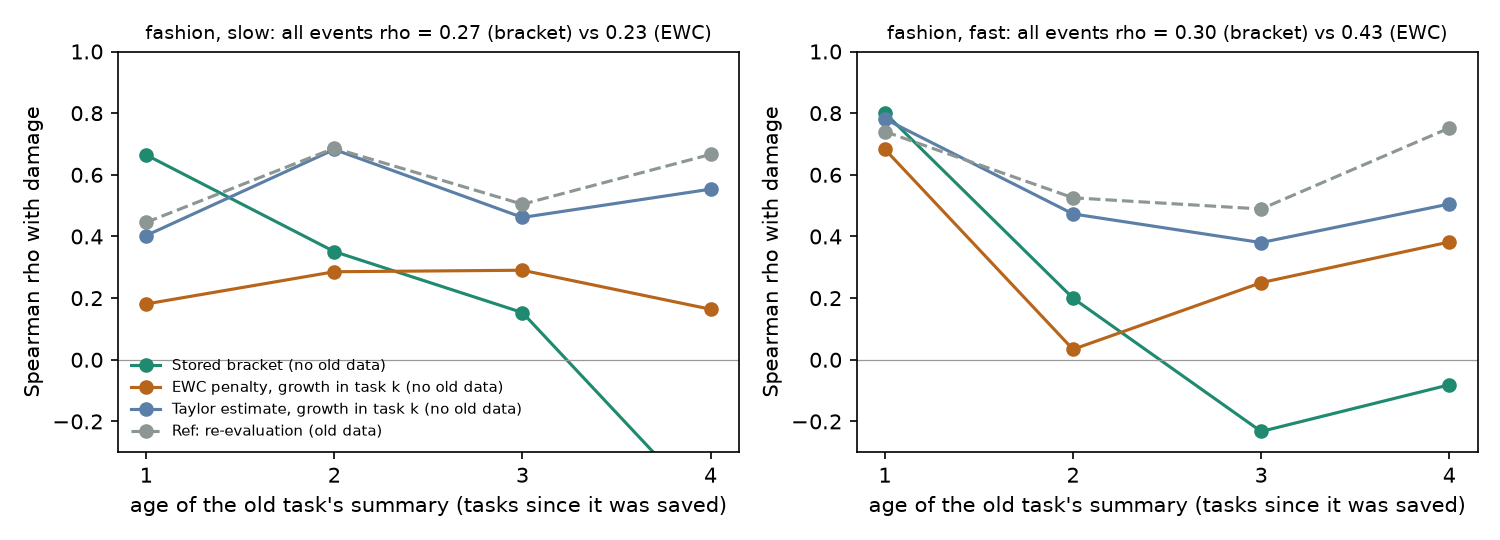

saved F:\forgetting\results_seq_fashion\seq_fashion_by_age.png


In [24]:
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, sc in zip(axs, ["task", "domain"]):
    f = os.path.join(RESULTS_DIR, f"seq_{DATASET}_{sc}_lr0.05.json")
    if not os.path.exists(f): ax.set_visible(False); continue
    Sm = json.load(open(f)); ages = list(Sm["by_age"].keys())
    for k, col, ls in [("bracket_stored", "#1F8A70", "-"), ("ewc_penalty", "#B8651C", "-"), ("est_watch", "#5B7FA6", "-"),
                       ("simple_check", "#8C9694", "--")]:
        ax.plot([int(a) for a in ages], [Sm["by_age"][a]["rho"][k] for a in ages], marker="o", color=col, ls=ls, label=LABELS[k])
    ax.axhline(0, color="#999", lw=0.6); ax.set_ylim(-0.3, 1.0); ax.set_xticks([int(a) for a in ages])
    ax.set_xlabel("age of the old task's summary (tasks since it was saved)"); ax.set_ylabel("Spearman rho with damage")
    ax.set_title(f"{DATASET}, {'slow' if sc == 'task' else 'fast'}: all events rho = {Sm['rho']['bracket_stored']:.2f} (bracket) vs {Sm['rho']['ewc_penalty']:.2f} (EWC)", fontsize=9)
axs[0].legend(fontsize=7, frameon=False, loc="lower left")
out = os.path.join(RESULTS_DIR, f"seq_{DATASET}_by_age.png"); fig.tight_layout(); fig.savefig(out, dpi=150); plt.close(fig)
display(Image(out)); print("saved", out)